# KYC: umbrales económicos y capacidad de revisión

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Costo sin capacidad (COP):** 8025285.9
- **Costo con 60 minutos (COP):** 4274124.94
- **Costo adicional con eficacia cero (COP):** 120006.94
- **Umbral de revisión para 2 millones:** 0.02043
- **EVSI neto con p=0,05 (COP):** 14290.5
- **Brecha sobre límite dual de grilla (COP):** -0.0

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Cuándo conviene verificar, revisar o continuar? Derivamos el umbral económico y pasamos de decisiones aisladas a una asignación bajo un presupuesto común.

### Supuestos y población

Los casos son independientes. Probabilidad, pérdida neta, eficacia y fricción son supuestos numéricos; no hay rechazo automático ni efecto causal estimado.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. Derivar el beneficio y el umbral


$$C_i(a)=p_iL_i(1-q_a)+c_a+(1-p_i)f_a,\quad B_i(a)=p_iL_iq_a-c_a-(1-p_i)f_a.$$

Si $Lq+f>0$, $B>0$ equivale a $p>(c+f)/(Lq+f)$. No existe un umbral universal de 0,5. Si el denominador es cero, comparar costos directamente.

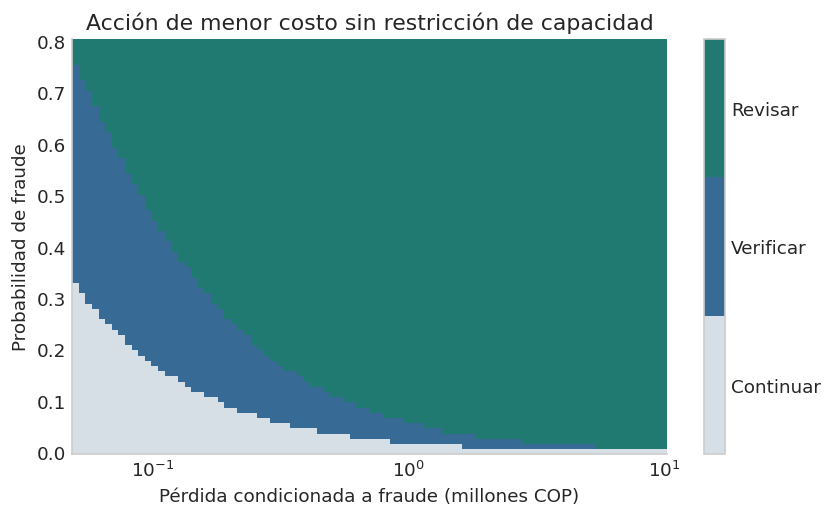

In [2]:
actions=[Action('allow',0,0,0,0),Action('verify',.35,4000,2500,3),Action('review',.8,18000,15000,15)]
loss_grid=np.geomspace(50_000,10_000_000,90)
p_grid=np.linspace(.001,.8,80)
cost_tensor=np.array([[[expected_cost(Case('grid',float(p),float(L)),a) for a in actions] for L in loss_grid] for p in p_grid])
choices=np.argmin(cost_tensor,axis=2)
from matplotlib.colors import ListedColormap
fig,ax=plt.subplots();im=ax.pcolormesh(loss_grid/1e6,p_grid,choices,cmap=ListedColormap(['#D6DFE5',BLUE,TEAL]),vmin=-.5,vmax=2.5,shading='auto')
ax.set(xscale='log',xlabel='Pérdida condicionada a fraude (millones COP)',ylabel='Probabilidad de fraude',title='Acción de menor costo sin restricción de capacidad')
cb=fig.colorbar(im,ax=ax,ticks=[0,1,2]);cb.ax.set_yticklabels(['Continuar','Verificar','Revisar']);plt.show()

El mapa se resuelve sin presupuesto común y solo muestra el efecto de monto y probabilidad. No debe interpretarse como política operativa: al limitar minutos, algunos casos reciben otra acción.

## 2. Elegir acciones conjuntamente


$$\min_{x_{ia}\in\{0,1\}}\sum_{ia}x_{ia}C_i(a),\quad\sum_a x_{ia}=1,\quad\sum_{ia}t_ax_{ia}\leq T.$$

Se compara el mismo conjunto de casos al aumentar capacidad. El conjunto factible crece: el costo óptimo no puede aumentar bajo los mismos supuestos.

,presupuesto_min,usado_min,costo_COP,revisiones,verificaciones
0,0,0.0000,"8,025,285.8963",0,0
1,15,15.0000,"6,321,145.4784",0,5
2,30,30.0000,"5,336,682.3812",1,5
3,60,60.0000,"4,274,124.9431",3,5
4,90,90.0000,"3,659,601.3042",4,10
5,150,150.0000,"2,928,901.8765",9,5


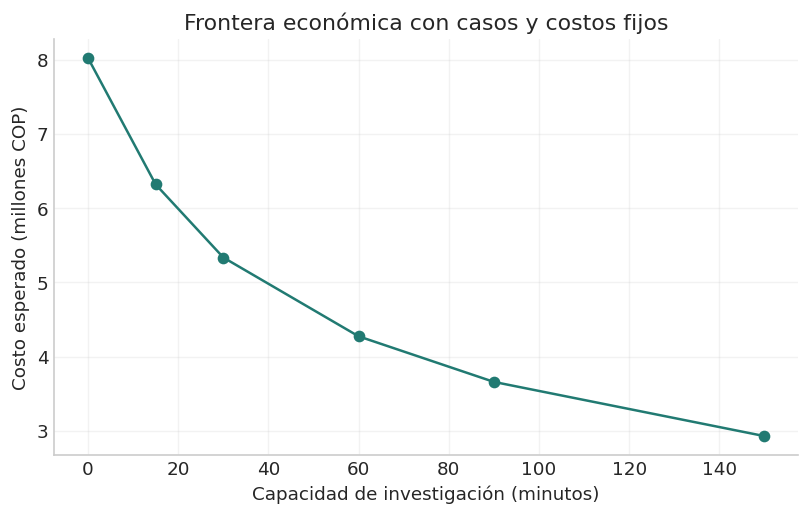

In [3]:
probabilities=rng.beta(1,8,35);losses=rng.lognormal(np.log(1_500_000),.8,35)
cases=[Case(f'synthetic-{i}',float(p),float(L)) for i,(p,L) in enumerate(zip(probabilities,losses))]
capacities=[0,15,30,60,90,150]
plans=[optimize(cases,actions,T) for T in capacities]
capacity_table=pd.DataFrame([{'presupuesto_min':T,'usado_min':p['effort_minutes'],'costo_COP':p['objective_cop'],'revisiones':p['actions'].count('review'),'verificaciones':p['actions'].count('verify')} for T,p in zip(capacities,plans)])
display(capacity_table)
fig,ax=plt.subplots();ax.plot(capacities,capacity_table['costo_COP']/1e6,color=TEAL,marker='o')
ax.set(xlabel='Capacidad de investigación (minutos)',ylabel='Costo esperado (millones COP)',title='Frontera económica con casos y costos fijos');plt.show()

La pendiente depende de casos concretos; no es una estimación del retorno de contratar investigadores. El presupuesto se aplica en minutos y puede quedar sin usar cuando la intervención no tiene beneficio.

## 3. Política congelada ante eficacia incierta


Se conserva el plan elegido con $T=60$ y se reevalúa con $q'_a=\gamma q_a$ acotado a 1. Esto es sensibilidad de supuestos, no recalibración con resultados de prueba.

In [4]:
frozen=plans[3];lookup={a.name:a for a in actions}
no_action=sum(expected_cost(case,actions[0]) for case in cases)
sensitivity=[]
for gamma in [0,.25,.5,.75,1,1.25]:
    scenario=Scenario('efficacy',effectiveness_multiplier=gamma)
    total=sum(expected_cost(case,lookup[a],scenario) for case,a in zip(cases,frozen['actions']))
    sensitivity.append({'gamma':gamma,'costo_COP':total,'beneficio_vs_continuar_COP':no_action-total})
display(pd.DataFrame(sensitivity))

,gamma,costo_COP,beneficio_vs_continuar_COP
0,0.0000,"8,145,292.8359","-120,006.9397"
1,0.2500,"7,177,500.8627","847,785.0335"
2,0.5000,"6,209,708.8895","1,815,577.0067"
3,0.7500,"5,241,916.9163","2,783,368.9800"
4,1.0000,"4,274,124.9431","3,751,160.9532"
5,1.2500,"3,306,332.9699","4,718,952.9264"


Con eficacia cero no hay prevención, pero persisten costos y fricción. Una probabilidad bien estimada no basta: la intervención necesita demostrar utilidad y el supuesto de eficacia debe investigarse.

## Desarrollo ampliado: modelo, estimación y uso


**Uso:** decidir qué solicitud requiere información adicional cuando no alcanza la capacidad para revisar todas. **Entrada:** probabilidad con población/versión, pérdida neta en COP, costos, eficacia y minutos. **Salida:** acción sugerida y costo bajo supuestos. No se deriva una política de aprobación de crédito completa.

El costo esperado supone casos independientes y una acción por caso. El monto es pérdida condicionada a fraude y no necesariamente saldo total. La fricción corresponde a clientes legítimos. La eficacia de la acción y la calidad de una prueba informativa son conceptos distintos; los ejercicios siguientes los separan.

In [5]:
advanced_metrics = {}
advanced_rng = np.random.default_rng(9221)

### 4. Umbral con ejemplo numérico completo


De $B=pLq-c-(1-p)f$ se obtiene $B=p(Lq+f)-(c+f)$. La frontera es
$$p^*=\frac{c+f}{Lq+f},\quad\frac{\partial p^*}{\partial L}=-\frac{q(c+f)}{(Lq+f)^2}.$$

Si $p^*>1$ no hay probabilidad admisible que justifique la acción bajo ese costo. Un umbral bajo no elimina la restricción de capacidad.

In [6]:
review=actions[2]
example_loss=2_000_000.
threshold=(review.cost_cop+review.legitimate_friction_cop)/(example_loss*review.prevent_fraction+review.legitimate_friction_cop)
example_rows=[]
for probability in [threshold/2,threshold,threshold*2,.2]:
    case=Case('example',float(probability),example_loss)
    allow_cost=expected_cost(case,actions[0]);review_cost=expected_cost(case,review)
    example_rows.append({'p':probability,'continuar_COP':allow_cost,'revisar_COP':review_cost,'beneficio_COP':allow_cost-review_cost})
display(pd.DataFrame(example_rows))
assert abs(example_rows[1]['beneficio_COP'])<1e-6

,p,continuar_COP,revisar_COP,beneficio_COP
0,0.0102,"20,433.4365","36,933.4365","-16,500.0000"
1,0.0204,"40,866.8731","40,866.8731",0.0000
2,0.0409,"81,733.7461","48,733.7461","33,000.0000"
3,0.2000,"400,000.0000","110,000.0000","290,000.0000"


**Interpretación y uso.** El mismo cálculo puede documentarse para un comité de riesgo con moneda, horizonte y fuente de cada parámetro. No interpretar el umbral de este ejemplo como apetito institucional de fraude.

### 5. Valor de información: verificar antes de actuar


Para una prueba binaria Z con sensibilidad s y falso positivo f, $P(Z=1)=ps+(1-p)f$. Cada resultado actualiza p por Bayes. El valor esperado de información muestral neto es
$$EVSI=\min_a C(a,p)-\sum_z P(z)\min_a C(a,p_z)-c_Z.$$

La prueba de este ejercicio solo informa: no previene directamente. Sus costos no deben sumarse otra vez como eficacia q del motor.

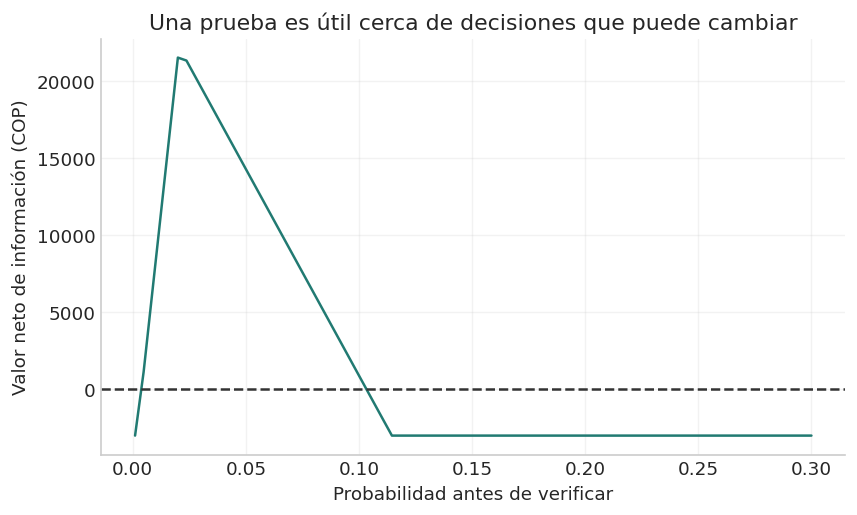

In [7]:
terminal_actions=[actions[0],actions[2]]
verification_sensitivity,verification_fp,test_cost=.85,.07,3000.
def info_value(p,L,test_fee=test_cost):
    positive=p*verification_sensitivity+(1-p)*verification_fp
    negative=1-positive
    p_pos=p*verification_sensitivity/positive
    p_neg=p*(1-verification_sensitivity)/negative
    baseline=min(expected_cost(Case('info',p,L),a) for a in terminal_actions)
    posterior_cost=positive*min(expected_cost(Case('pos',p_pos,L),a) for a in terminal_actions)+negative*min(expected_cost(Case('neg',p_neg,L),a) for a in terminal_actions)
    return baseline-posterior_cost-test_fee,positive,p_pos,p_neg
information=[]
for probability in np.linspace(.001,.3,80):
    evsi,z_prob,p_pos,p_neg=info_value(float(probability),example_loss)
    information.append({'p':probability,'EVSI_COP':evsi})
information=pd.DataFrame(information)
fig,ax=plt.subplots();ax.plot(information['p'],information['EVSI_COP'],color=TEAL)
ax.axhline(0,color='#333333',linestyle='--');ax.set(xlabel='Probabilidad antes de verificar',ylabel='Valor neto de información (COP)',title='Una prueba es útil cerca de decisiones que puede cambiar');plt.show()
value,zp,pp,pn=info_value(.05,example_loss)
assert np.isclose(zp*pp+(1-zp)*pn,.05)

**Interpretación y uso.** La probabilidad posterior promedio conserva el prior. El beneficio surge al cambiar una decisión, no al aumentar siempre el score. Si el resultado no modifica ninguna acción, la información no justifica su costo en este modelo.

### 6. Límite de información perfecta y costo máximo


La información perfecta revela Y antes de elegir acción. Su costo esperado es
$$C_{PI}=p\min_a C(a,1)+(1-p)\min_a C(a,0).$$

La información muestral sin costo no puede valer más que la perfecta en el modelo especificado. La comparación se hace con el mismo menú de acciones y sin costo de esperar.

In [8]:
info_checks=[]
for probability in [.005,.02,.05,.1,.2]:
    base=min(expected_cost(Case('x',probability,example_loss),a) for a in terminal_actions)
    perfect=probability*min(expected_cost(Case('fraud',1.,example_loss),a) for a in terminal_actions)+(1-probability)*min(expected_cost(Case('legit',0.,example_loss),a) for a in terminal_actions)
    sample_free=info_value(probability,example_loss,test_fee=0)[0]
    info_checks.append({'p':probability,'EVPI_COP':base-perfect,'EVSI_sin_costo_COP':sample_free})
info_checks=pd.DataFrame(info_checks);display(info_checks)
assert (info_checks['EVSI_sin_costo_COP']>=-1e-7).all()
assert (info_checks['EVSI_sin_costo_COP']<=info_checks['EVPI_COP']+1e-7).all()

,p,EVPI_COP,EVSI_sin_costo_COP
0,0.0050,"7,910.0000","4,425.0500"
1,0.0200,"31,640.0000","24,630.2000"
2,0.0500,"31,350.0000","17,290.5000"
3,0.1000,"29,700.0000","3,891.0000"
4,0.2000,"26,400.0000",-0.0000


**Interpretación y uso.** El límite permite detectar doble conteo o una actualización de Bayes incoherente. La información perfecta no significa pérdida cero: revisar un fraude tiene costo y eficacia menor que uno.

### 7. Capacidad, costo sombra y límite dual


Al relajar la capacidad con $\lambda\ge0$:
$$g(\lambda)=\sum_i\min_a[C_i(a)+\lambda t_a]-\lambda T.$$

Cada g es un límite inferior del costo mínimo. El MILP es discreto; maximizar este dual no necesariamente recupera su valor exacto. Lambda se interpreta como COP por minuto en el problema relajado, no como salario óptimo de un analista.

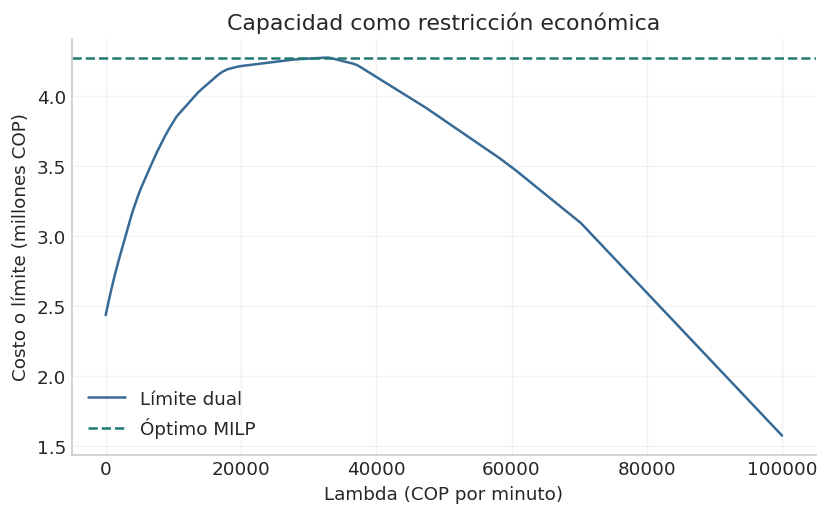

In [9]:
T=60.
base_cost=np.array([[expected_cost(case,a) for a in actions] for case in cases])
effort=np.array([a.effort_minutes for a in actions])
lambdas=np.linspace(0,100_000,250)
dual=np.array([np.min(base_cost+lam*effort,axis=1).sum()-lam*T for lam in lambdas])
primal=plans[3]['objective_cop']
fig,ax=plt.subplots();ax.plot(lambdas,dual/1e6,color=BLUE,label='Límite dual')
ax.axhline(primal/1e6,color=TEAL,linestyle='--',label='Óptimo MILP')
ax.set(xlabel='Lambda (COP por minuto)',ylabel='Costo o límite (millones COP)',title='Capacidad como restricción económica');ax.legend();plt.show()
assert np.max(dual)<=primal+1e-5
advanced_metrics.update({'Umbral de revisión para 2 millones':round(float(threshold),5),'EVSI neto con p=0,05 (COP)':round(float(value),2),'Brecha sobre límite dual de grilla (COP)':round(float(primal-dual.max()),2)})

**Interpretación y uso.** La grilla aproxima el mejor dual y no certifica su máximo continuo. El solver conserva su propia verificación de integralidad y restricciones. Para colas y casos relacionados habría que cambiar la formulación, no reutilizar el mismo límite sin más.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [10]:
assert all(a['objective_cop']>=b['objective_cop']-1e-6 for a,b in zip(plans,plans[1:]))
assert sensitivity[0]['beneficio_vs_continuar_COP'] < 0
assert plans[0]['actions']==['allow']*len(cases)

## Resultados computados

In [11]:
metrics = {'Costo sin capacidad (COP)': round(plans[0]['objective_cop'],2), 'Costo con 60 minutos (COP)': round(plans[3]['objective_cop'],2), 'Costo adicional con eficacia cero (COP)': round(-sensitivity[0]['beneficio_vs_continuar_COP'],2)}
metrics.update(advanced_metrics)
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Costo sin capacidad (COP)": 8025285.9, "Costo con 60 minutos (COP)": 4274124.94, "Costo adicional con eficacia cero (COP)": 120006.94, "Umbral de revisión para 2 millones": 0.02043, "EVSI neto con p=0,05 (COP)": 14290.5, "Brecha sobre límite dual de grilla (COP)": -0.0}


## Ideas y preguntas para continuar

1. Estimar eficacia por tipo de verificación con un piloto defendible.
2. Añadir tiempo por caso y dos recursos: analista y proveedor.
3. Comparar valor de información de una verificación antes de decidir la revisión.
4. Incorporar demoras y abandono de clientes legítimos como resultados separados.

## Fuentes y relación con el proyecto

- Motor local: `../../loss-minimization-engine/src/engine.py`.
- [SciPy MILP](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html).

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.

## Uso responsable y ficha mínima de salida

Antes de una aplicación institucional, registrar población, corte de información, versión del modelo, horizonte, unidades y cobertura de fuentes. Separar score de anomalía, probabilidad estimada y costo por acción. Una discrepancia o un desvío requiere evidencia independiente antes de llamarlo fraude. El experimento está completo en su alcance sintético; no sustituye calibración externa, integración de datos o validación independiente.

## Preguntas para refutar el desarrollo

1. ¿La mejora persiste al cambiar el mecanismo generador y la cohorte?
2. ¿Qué variable solo estaría disponible después de decidir?
3. ¿Cuánto del beneficio depende de una eficacia o cobertura supuesta?
4. ¿Qué caso legítimo produce la misma señal?
5. ¿Puede otra persona reconstruir el resultado desde las celdas y los parámetros?

## Diccionario de símbolos y unidades

| Símbolo | Significado en este notebook | Unidad o restricción |
|---|---|---|
| p | Probabilidad de fraude | Fracción calibrada en su población |
| L | Pérdida neta condicionada a fraude | COP, horizonte común |
| q | Fracción prevenible por acción | Supuesto de eficacia, no sensibilidad de prueba |
| c, f | Costo de acción y fricción legítima | COP por caso |
| t, T | Tiempo por acción y capacidad | Minutos |
| λ | Multiplicador dual de capacidad | COP por minuto |
| EVSI, EVPI | Valor de información muestral/perfecta | COP; mismo menú de acciones |

## Modelos y casos de uso

| Modelo o técnica | Para qué usarlo | Condición para interpretar su salida |
|---|---|---|
| Costo por acción | Priorizar pérdida prevenible | Mantener fuente y sensibilidad de parámetros |
| MILP de capacidad | Asignar acciones indivisibles | Casos independientes y menú explícito |
| EVSI/EVPI | Decidir si pedir una nueva verificación | Modelar positivos, negativos e inconclusos |
| Relajación dual | Contrastar el costo óptimo y la capacidad | Límite del problema relajado, no retorno salarial |

Referencias técnicas adicionales: [logit](https://scikit-learn.org/stable/modules/linear_model.html), [beta-binomial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.betabinom.html), [MILP](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html). Las distribuciones, datos y resultados de este notebook son sintéticos y se generan en las celdas.